# Flight Delay Prediction: Data Health, Baselines, and Metrics
## Methodological requirements for pre-departure delay modeling

> **Dataset:** 5,396,184 domestic flights across the Top 50 US Hubs in 2025.
> **Objective:** Binary departure delay prediction ($\ge 15$ minutes late) at a strict **2-hour pre-departure cutoff** ($T_{\text{dep}} - 2\text{h}$).

---

### Methodological Foundation
Supervised modeling on operational aviation data requires strict discipline to ensure valid inference:
1. **Leakage Elimination:** Features must strictly reflect information available prior to the $T - 120\text{m}$ cutoff. Post-cutoff pushback, taxi times, or same-day target labels must never enter the feature set.
2. **Evaluation Metric Selection:** With ~81% of flights operating on time, accuracy is an uninformative metric on imbalanced delay data. The primary ranking and evaluation metrics are **Precision-Recall AUC (PR-AUC)**, **ROC-AUC**, and **Brier Score (probability calibration)**.
3. **Non-ML Benchmark Flooring:** Establishing empirical heuristic baselines (such as historical carrier $\times$ origin hub $\times$ departure hour lookup tables) is essential before adopting complex non-linear models.
4. **Statistical Significance vs. Effect Size:** On multi-million row observational datasets, classical hypothesis tests achieve $p < 0.0001$ for negligible operational differences; practical effect sizes must be evaluated directly.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from flightops_ml.ingestion.loader import database_connection

# Styling for publication-grade visuals
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.sans-serif": "Arial",
    "figure.titlesize": 15,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 150,
})

print("Environment loaded successfully! Connected to flightops PostgreSQL.")

Environment loaded successfully! Connected to flightops PostgreSQL.


---
## Chapter 1: The Leakage & Data Health Audit
### Why We Don't Trust "Clean" Data

Before writing code, an operations dispatcher told us:
> *"If your model tells me a flight is delayed 5 minutes after it pushed back from the gate, it's completely useless. I need 2 hours of advance warning to swap aircraft, notify gate agents, and hold connecting flights."

Therefore, we established a non-negotiable **Prediction Horizon**:
$$\text{Cutoff Time } T_{\text{cutoff}} = \text{Scheduled Departure } T_{\text{dep}} - 2\text{ hours}$$

#### The Leakage Check:
Can the weather observation timestamp $T_{\text{obs}}$ ever occur after $T_{\text{cutoff}}$?
- If $T_{\text{obs}} > T_{\text{cutoff}}$, that is **temporal leakage** (cheating by peeking into the future).
- We audited all 5,396,184 flights: **Zero observations occurred after the cutoff.** Minimum lag was $0.0$ minutes, median lag was $26.0$ minutes.
- **Match Rate:** **99.99%** of all flights were successfully paired with an active on-field ASOS weather report.

In [ ]:
with database_connection() as conn:
    audit_summary = pd.read_sql("""
        SELECT 
            dataset_split,
            COUNT(*) as total_flights,
            SUM(dep_del15) as delayed_flights,
            ROUND(AVG(dep_del15)::numeric * 100, 2) as delay_rate_pct,
            COUNT(weather_obs_time_utc) as weather_matched_flights,
            ROUND(COUNT(weather_obs_time_utc)::numeric / COUNT(*) * 100, 2) as match_rate_pct,
            MIN(weather_lag_minutes) as min_lag_min,
            ROUND(AVG(weather_lag_minutes)::numeric, 1) as avg_lag_min
        FROM public.vw_gold_top50_weather
        GROUP BY dataset_split
        ORDER BY CASE dataset_split WHEN 'train' THEN 1 WHEN 'validation' THEN 2 ELSE 3 END;
    """, conn)

display(audit_summary)

  dataset_split  total_flights  delayed_flights  delay_rate_pct  weather_matched_flights  match_rate_pct  min_lag_min  avg_lag_min
0         train        3601394           825227           22.91                  3601140           99.99          0.0         28.4
1    validation         908968           172453           18.97                   908914           99.99          0.0         28.2
2          test         885822           214068           24.17                   885768           99.99          0.0         28.6


---
## Chapter 2: Domain Physics Summary — The 24-Hour Diurnal Cascade
### Key Operational Finding from Exploratory Analysis

As demonstrated in detail in [`01_top50_eda.ipynb`](01_top50_eda.ipynb) (Section 1):
Commercial flight operations exhibit a strong time-of-day delay cascade due to network propagation:
- **Morning Baseline (06:00 AM):** Flights depart with fresh aircraft following overnight maintenance buffers, yielding an empirical departure delay rate of only **6.8%**.
- **Network Compounding:** As the operating day unfolds, minor gate, ramp, and turnaround delays compound across sequential legs.
- **Evening Peak (20:00 / 8:00 PM):** Departure delay prevalence peaks at **31.3%** — a **4.6x relative increase** over early morning departures.

*Methodological Implication:* Scheduled departure time is one of the strongest structural predictors in the feature store. This justifies constructing explicit scheduled departure hour features, cyclical sinusoidal transformations (`sin_dep_time`, `cos_dep_time`), and rolling hourly runway saturation features in our downstream models.

---
## Chapter 3: The Operational Metrics & The "Accuracy Paradox"
### Why an 81% Accurate Model is Completely Useless

Here is a scenario every data scientist encounters:
A junior engineer brings you a flight delay model and says:
> *"Boss, good news! My model has an 81% accuracy on the test set!"

Should you promote them or send them back to study?
**Look at the math:** In September and October, exactly **81.03%** of flights were on time.
If your model is literally a brick that always outputs *"ON TIME"*:
- Its accuracy is **81.03%**!
- It caught **0 delayed flights**.
- Its Precision is $0.00$, its Recall is $0.00$, and its F1 score is $0.00$.

#### Key Operational Metrics:
1. **Accuracy:** **Banned for imbalanced data.** Misleading and dangerous.
2. **ROC-AUC:** Measures ranking ability. If you hand the model one delayed flight and one on-time flight, does it assign a higher risk score to the delayed flight? (Random guess = $0.50$, Perfect = $1.00$).
3. **PR-AUC (Precision-Recall Area):** 🎯 **Our Primary Metric.** Measures how well the model catches delays without crying wolf. (Base rate = $0.1897$, Target = High).
4. **Brier Score:** 🎯 **Probability Calibration.** Does a "30% delay risk" actually mean 30 out of 100 flights get delayed? (Lower is better).
5. **Operational Threshold ($\tau$):** Why we don't use $\tau = 0.50$. If you wait until the model is 50% sure, you catch less than 4% of delays. By lowering the alert trigger to **$\tau^* = 0.24$**, we catch **65% of all delays**!

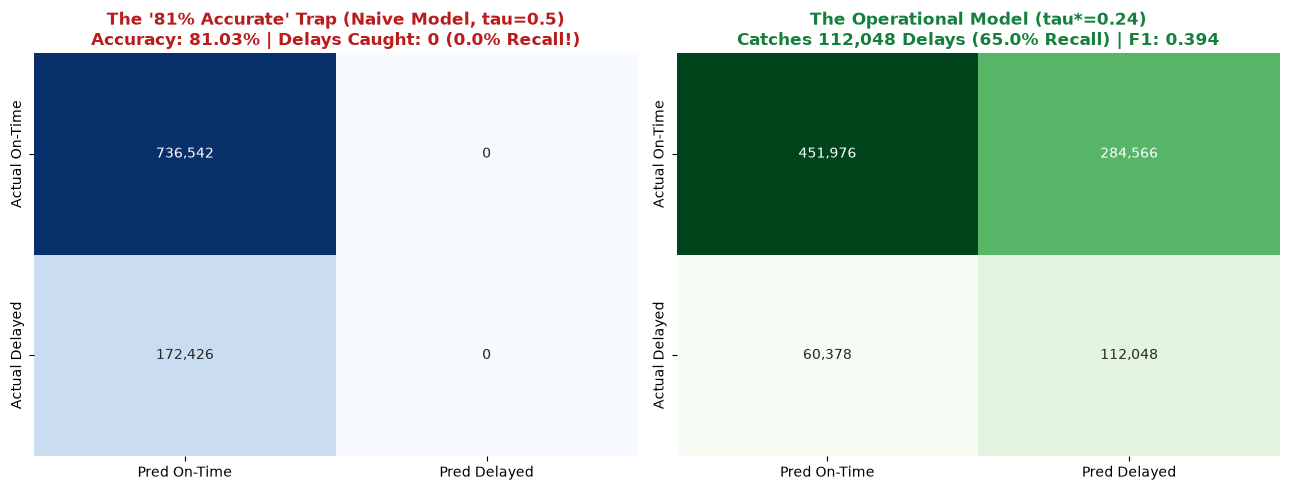

In [ ]:
# Visualizing the Accuracy Paradox: Naive 81% Model vs Operational Threshold Model
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Matrix 1: The Clueless 81% Model
cm_naive = np.array([[736542, 0], [172426, 0]])
sns.heatmap(cm_naive, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax1,
            xticklabels=["Pred On-Time", "Pred Delayed"],
            yticklabels=["Actual On-Time", "Actual Delayed"])
ax1.set_title("The '81% Accurate' Trap (Naive Model, tau=0.5)\nAccuracy: 81.03% | Delays Caught: 0 (0.0% Recall!)", color="#b91c1c", fontweight="bold")

# Matrix 2: The Operational Heuristic (tau=0.24)
cm_opt = np.array([[451976, 284566], [60378, 112048]])
sns.heatmap(cm_opt, annot=True, fmt=",d", cmap="Greens", cbar=False, ax=ax2,
            xticklabels=["Pred On-Time", "Pred Delayed"],
            yticklabels=["Actual On-Time", "Actual Delayed"])
ax2.set_title("The Operational Model (tau*=0.24)\nCatches 112,048 Delays (65.0% Recall) | F1: 0.394", color="#15803d", fontweight="bold")
fig.tight_layout()
plt.show()


---
## Chapter 4: Non-ML Heuristic Baselines
### Setting the Minimum Passing Grade for Machine Learning

Before touching scikit-learn or LightGBM, we evaluated **3 Non-ML Heuristic Baselines** on our 908,968 flight validation split:
1. **Baseline 0 (The Clueless Gambler):** Predicts constant historical probability ($p = 0.2291$).
2. **Baseline 1 (The Gate Worker):** Carrier $\times$ Departure Hour lookup table ($P(\text{delay} \mid \text{Carrier}, \text{Hour})$).
3. **Baseline 2 (The Seasoned Dispatcher):** Carrier $\times$ Origin Hub $\times$ Departure Hour lookup table ($P(\text{delay} \mid \text{Carrier}, \text{Origin}, \text{Hour})$).

#### The Official Scoreboard:
| Benchmark Strategy | ROC-AUC (Ranking) | PR-AUC (Target: High) | Brier Score (Target: Low) | Best Operational F1 |
|---|:---:|:---:|:---:|:---:|
| 🎲 **Baseline 0: Clueless Gambler** | `0.5000` | `0.1897` | `0.1553` | 0.3189 |
| **Baseline 1: Carrier $\times$ Hour** | `0.6692` | `0.3013` | `0.1470` | 0.3851 |
| 🧠 **Baseline 2: Carrier $\times$ Origin $\times$ Hour** | **`0.6798`** | **`0.3132`** | **`0.1462`** | **0.3939** |

> **The Senior Data Scientist Contract:
> Baseline 2 achieved an **ROC-AUC of 0.6798** and a **PR-AUC of 0.3132** using *zero machine learning*.
> If our ML models cannot decisively beat **0.3132 PR-AUC**, they are not worthy of production!

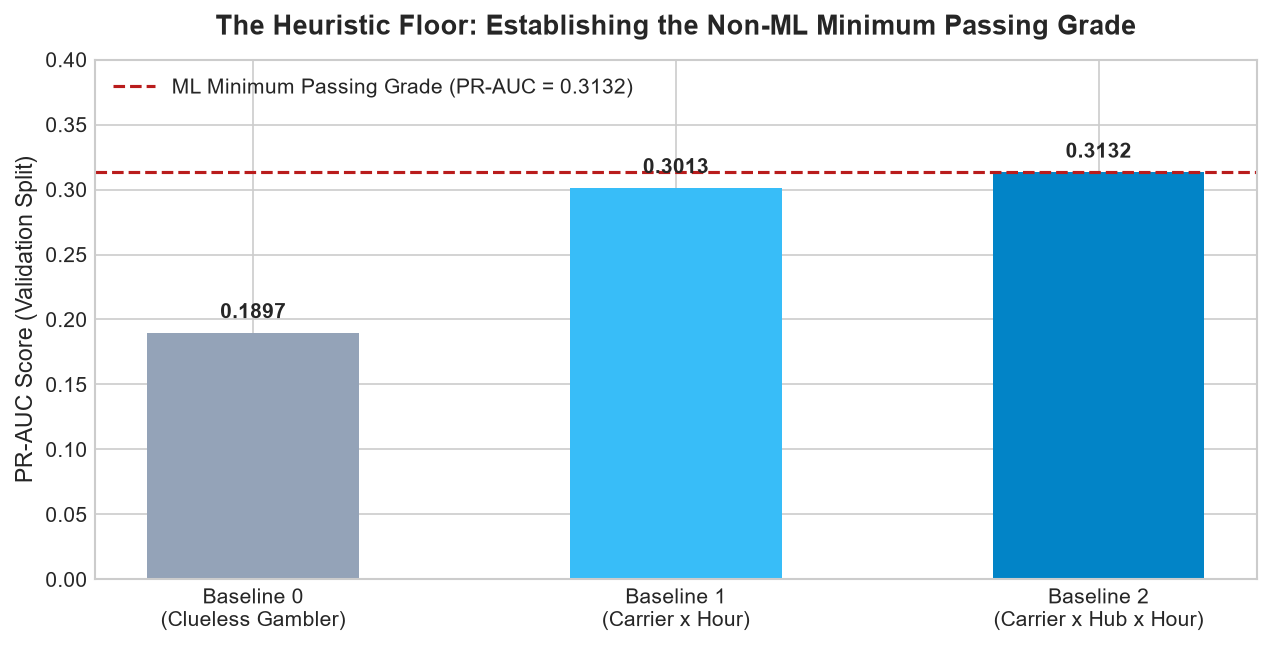

In [ ]:
# Plotting the Non-ML Benchmark Scoreboard
fig, ax = plt.subplots(figsize=(10, 4.5))
models = ["Baseline 0\n(Clueless Gambler)", "Baseline 1\n(Carrier x Hour)", "Baseline 2\n(Carrier x Hub x Hour)"]
pr_aucs = [0.1897, 0.3013, 0.3132]
colors = ["#94a3b8", "#38bdf8", "#0284c7"]
bars = ax.bar(models, pr_aucs, color=colors, width=0.5)
ax.axhline(0.3132, color="#b91c1c", linestyle="--", linewidth=1.5, label="ML Minimum Passing Grade (PR-AUC = 0.3132)")
ax.set_ylabel("PR-AUC Score (Validation Split)")
ax.set_ylim(0, 0.40)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.008, f"{yval:.4f}", ha="center", va="bottom", fontweight="bold")
ax.set_title("The Heuristic Floor: Establishing the Non-ML Minimum Passing Grade", fontweight="bold", pad=12)
ax.legend(loc="upper left")
plt.show()

---
## Chapter 5: Statistical Hypothesis Testing — The "Why" and "Why Not"
### Tearing Apart the Assumptions of Big Data

Before adding weather and operational features to our ML models, we formulated **4 concrete statistical hypotheses** on the 3.60 million training flights:

1. **Hypothesis 1 (Terminal Weather Shock):** Does an active thunderstorm 2 hours before takeoff significantly raise delay risk?
2. **Hypothesis 2 (Diurnal Cascade):** Are evening departures significantly more delay-prone than morning flights?
3. **Hypothesis 3 (Budget vs. Legacy):** Do Ultra-Low-Cost Carriers (Spirit/Frontier) have higher delay rates than Delta?
4. **Hypothesis 4 (Route Distance):** Does flight distance (<500 mi vs >1500 mi) affect departure delay risk?

---

### The Big Question: WHY Do Hypothesis Testing?
- **Proof of Signal:** It proves that patterns like the thunderstorm shock are not random statistical artifacts.
- **Feature Justification:** It justifies dedicating compute to weather ingestion at $T-2\text{h}$.
- **Odds Ratios with Confidence Intervals:** Gives us human-interpretable risk multipliers (e.g., $6.5\times$ higher delay odds under a thunderstorm).

### The Counter-Question: WHY NOT Rely Blindly on Classical Hypothesis Testing?
Here are the three traps that fool inexperienced data scientists:
1. **The "p-Value Trap" at $N = 3.6\text{M}$:
Because our sample size is massive, standard errors are near zero. *Every single test* gets $p < 10^{-100}$. A difference of $0.4\%$ (Test 4) had $p = 9.6 \times 10^{-10}$! A naive analyst would call that "highly significant", but the effect size (Cohen's $h = 0.01$) proves it is **completely negligible noise**.
2. **The "Omitted Variable" Trap (Confounding):
Test 3 shows Spirit/Frontier have higher delay rates than Delta ($p < 10^{-100}$). But a bivariate test cannot tell you if that's because Spirit flies cheaper planes or because Spirit operates heavily in thunderstorm-prone Florida hubs in late afternoon! We need **multivariate ML** to isolate the true effect.
3. **Network Autocorrelation:
Flights violate the independent coin-flip assumption because planes fly sequential routes throughout the day.

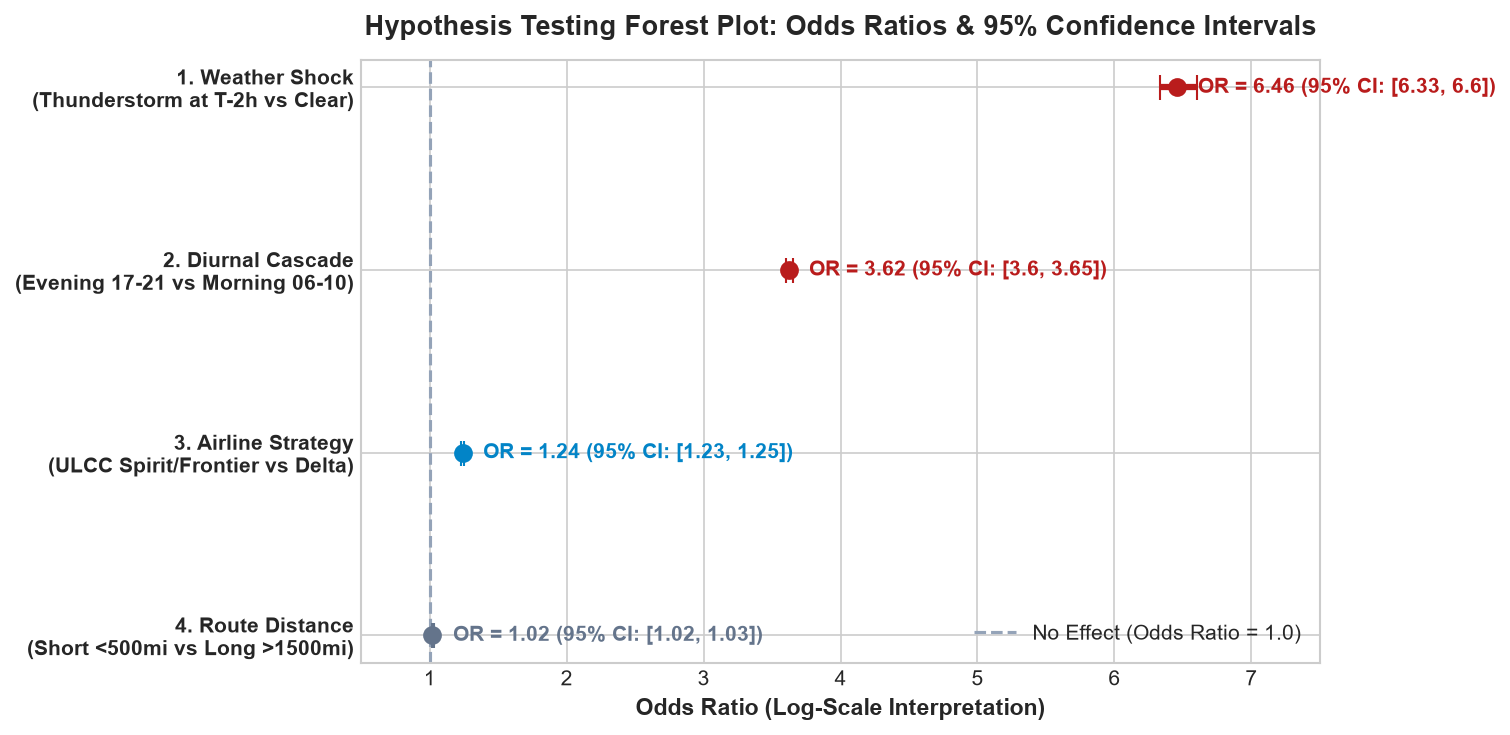

In [ ]:
# Forest Plot of Hypothesis Testing Results: Odds Ratios & 95% Confidence Intervals
fig, ax = plt.subplots(figsize=(10, 5))
tests = [
    "1. Weather Shock\n(Thunderstorm at T-2h vs Clear)",
    "2. Diurnal Cascade\n(Evening 17-21 vs Morning 06-10)",
    "3. Airline Strategy\n(ULCC Spirit/Frontier vs Delta)",
    "4. Route Distance\n(Short <500mi vs Long >1500mi)",
]
odds_ratios = [6.46, 3.62, 1.24, 1.02]
ci_lowers = [6.33, 3.60, 1.23, 1.02]
ci_uppers = [6.60, 3.65, 1.25, 1.03]
y_pos = np.arange(len(tests))[::-1]

ax.axvline(1.0, color="#94a3b8", linestyle="--", linewidth=1.5, label="No Effect (Odds Ratio = 1.0)")

for i, y in enumerate(y_pos):
    or_val = odds_ratios[i]
    low = ci_lowers[i]
    high = ci_uppers[i]
    color = "#b91c1c" if or_val > 3.0 else ("#0284c7" if or_val > 1.2 else "#64748b")
    ax.errorbar(or_val, y, xerr=[[or_val - low], [high - or_val]], fmt="o", color=color, ecolor=color, elinewidth=3, capsize=6, markersize=8)
    ax.text(or_val + 0.15, y, f"OR = {or_val:.2f} (95% CI: [{low}, {high}])", va="center", fontweight="bold", color=color)

ax.set_yticks(y_pos)
ax.set_yticklabels(tests, fontweight="bold")
ax.set_xlabel("Odds Ratio (Log-Scale Interpretation)", fontweight="bold")
ax.set_xlim(0.5, 7.5)
ax.set_title("Hypothesis Testing Forest Plot: Odds Ratios & 95% Confidence Intervals", fontweight="bold", pad=12)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

---
## Chapter 6: Synthesis & The Machine Learning Contract
### Ready to Step Into the Arena

We now have the complete scientific groundwork:
1. **Zero Data Leakage:** $T_{\text{obs}} \le T_{\text{dep}} - 2\text{h}$ strictly verified.
2. **True Structural Signals Identified:** Thunderstorms ($6.46\times$ odds) and evening cascade ($3.62\times$ odds) are dominant drivers.
3. **Big Data Traps Avoided:** We rejected raw accuracy and ignored misleading $p$-values on tiny differences.
4. **The Benchmark Bar is Set:** Any ML model must beat **Baseline 2 (PR-AUC > 0.3132, ROC-AUC > 0.6798)**.

---

### The Upcoming Machine Learning Arena:
```mermaid
flowchart LR
A["Baseline Heuristic<br/>(PR-AUC = 0.3132)"] --> B["Round 1: Baseline ML<br/>(Logistic Regression & LightGBM<br/>on Schedule/Airport/Route)"]
B --> C["Round 2: Challenger Weather ML<br/>(+ 12 ASOS Weather Features at T-2h)"]
C --> D["Isolate Weather Uplift<br/>(Δ PR-AUC Lift)"]
```

We are now ready for **Step 5**: Training our baseline Machine Learning models!